# NHS.UK Health A-Z: representações e tarefas de PLN

Trabalho da Unidade 3. Equipe: Guilherme Moll


## 0. Dados e amostra

In [31]:
import gzip, json, re, time, unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 140)

SEMENTE = 42
FIGURAS = Path("figuras")
FIGURAS.mkdir(exist_ok=True)

with gzip.open("../data/passages.jsonl.gz", "rt", encoding="utf-8") as fh:
    passages = [json.loads(linha) for linha in fh]

print(f"passagens no corpus: {len(passages):,}")

passagens no corpus: 24,159


Limpeza e pré-processamento copiados da Etapa Prática 1

In [32]:
TAG = re.compile(r"<[^>]+>")
ENTIDADE = re.compile(r"&(?:[a-zA-Z]+|#\d+|#x[0-9a-fA-F]+);")
URL = re.compile(r"https?://\S+|www\.\S+")
ESPACOS = re.compile(r"[ \t\xa0]+")
LINHAS = re.compile(r"\n{2,}")

TIPOGRAFICOS = {"‘": "'", "’": "'", "“": '"', "”": '"',
                "–": "-", "—": "-", "…": "...", "­": ""}


def limpar(texto):
    if not texto:
        return ""
    texto = unicodedata.normalize("NFKC", texto)
    for de, para in TIPOGRAFICOS.items():
        texto = texto.replace(de, para)
    texto = ENTIDADE.sub(" ", TAG.sub(" ", texto))
    texto = URL.sub(" ", texto)
    texto = LINHAS.sub("\n", ESPACOS.sub(" ", texto))
    return "\n".join(l.strip() for l in texto.split("\n")).strip()

In [33]:
import nltk
for recurso in ("punkt", "punkt_tab", "stopwords"):
    nltk.download(recurso, quiet=True)

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

# Negação e modalidade
NEGACAO = frozenset({
    "no", "nor", "not", "don", "dont", "ain", "aren", "arent",
    "couldn", "couldnt", "didn", "didnt", "doesn", "doesnt",
    "hadn", "hadnt", "hasn", "hasnt", "haven", "havent", "isn", "isnt",
    "mightn", "mightnt", "mustn", "mustnt", "needn", "neednt",
    "shan", "shant", "shouldn", "shouldnt", "wasn", "wasnt",
    "weren", "werent", "won", "wont", "wouldn", "wouldnt",
    "against", "few", "more", "most", "very", "only", "same",
})
STOPWORDS = frozenset(stopwords.words("english")) - NEGACAO


def tokenizar(texto):
    return word_tokenize(texto, language="english")


def normalizar(tokens):
    return [t.casefold() for t in tokens if t.isalpha()]


def sem_stopwords(tokens):
    return [t for t in tokens if t not in STOPWORDS]


def preparar(texto):
    return sem_stopwords(normalizar(tokenizar(limpar(texto))))

remoção de duplicatas e textos com mais de um rótulo

amostragem: 4.000 passagens, todas as rotuladas + informativas sorteadas, BERT em CPU

In [34]:
corpus = pd.DataFrame(passages)
corpus["clean_text"] = corpus["raw_text"].map(limpar)
corpus["chave"] = corpus["clean_text"].str.casefold().str.split().str.join(" ")

rotulos_por_texto = corpus.groupby("chave")["urgency"].nunique()
ambiguos = set(rotulos_por_texto[rotulos_por_texto > 1].index)
unicos = corpus[~corpus["chave"].isin(ambiguos)].drop_duplicates("chave").copy()
unicos["tokens"] = [sem_stopwords(normalizar(tokenizar(t))) for t in unicos["clean_text"]]
unicos = unicos[unicos["tokens"].str.len() >= 3]

TAMANHO_BASE = 4000
rotuladas = unicos[unicos["urgency"] != "informational"]
informativas = unicos[unicos["urgency"] == "informational"].sample(
    TAMANHO_BASE - len(rotuladas), random_state=SEMENTE)
base = (pd.concat([rotuladas, informativas])
          .sample(frac=1, random_state=SEMENTE).reset_index(drop=True))

print(f"passagens sem duplicata : {len(unicos):,}")
print(f"textos com rótulo ambíguo: {len(ambiguos):,}")
print(f"base                     : {len(base):,}\n")
display(base["urgency"].value_counts().rename("passagens").to_frame())

passagens sem duplicata : 18,007
textos com rótulo ambíguo: 5
base                     : 4,000



,passagens
urgency,
informational,1614
self_care,940
urgent,568
non_urgent,531
emergency,347


## 1. Representações

BoW e TF-IDF sobre os tokens sem stopwords

In [35]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

bow = CountVectorizer(analyzer=lambda t: t, min_df=2)
tfidf = TfidfVectorizer(analyzer=lambda t: t, min_df=2)

X_bow = bow.fit_transform(base["tokens"])
X_tfidf = tfidf.fit_transform(base["tokens"])

print("BoW   :", X_bow.shape)
print("TF-IDF:", X_tfidf.shape)

BoW   : (4000, 4912)
TF-IDF: (4000, 4912)


Word2Vec treinado nas passagens sem duplicações

In [36]:
from gensim.models import Word2Vec

modelo_w2v = Word2Vec(
    sentences=unicos["tokens"].tolist(),
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    seed=SEMENTE,
    workers=1,
    epochs=10,
)


def vetor_w2v(tokens):
    vetores = [modelo_w2v.wv[t] for t in tokens if t in modelo_w2v.wv]
    if not vetores:
        return np.zeros(modelo_w2v.vector_size, dtype=np.float32)
    return np.mean(vetores, axis=0)


X_w2v = np.vstack([vetor_w2v(t) for t in base["tokens"]])

print("vocabulário:", len(modelo_w2v.wv))
print("Word2Vec   :", X_w2v.shape)
print("\nvizinhos de 'breathless':", [p for p, _ in modelo_w2v.wv.most_similar("breathless", topn=6)])

vocabulário: 10764
Word2Vec   : (4000, 100)

vizinhos de 'breathless': ['wheezing', 'deeply', 'clammy', 'wheezy', 'bout', 'headed']


BERT: `bert-base-uncased` no lugar do BERTimbau, já que o corpus está em inglês, e mean pooling

In [37]:
import torch
from transformers import AutoTokenizer, AutoModel
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()

MODELO_BERT = "bert-base-uncased"
tokenizer_bert = AutoTokenizer.from_pretrained(MODELO_BERT)
modelo_bert = AutoModel.from_pretrained(MODELO_BERT).eval()


def mean_pooling(last_hidden_state, attention_mask):
    mascara = attention_mask.unsqueeze(-1).expand(last_hidden_state.size()).float()
    soma = torch.sum(last_hidden_state * mascara, dim=1)
    return soma / torch.clamp(mascara.sum(dim=1), min=1e-9)


def gerar_embeddings_bert(textos, batch_size=16):
    lotes = []
    with torch.no_grad():
        for inicio in range(0, len(textos), batch_size):
            entradas = tokenizer_bert(textos[inicio:inicio + batch_size], padding=True,
                                      truncation=True, max_length=128, return_tensors="pt")
            saida = modelo_bert(**entradas)
            lotes.append(mean_pooling(saida.last_hidden_state, entradas["attention_mask"]).numpy())
    return np.vstack(lotes)


inicio = time.time()
X_bert = gerar_embeddings_bert(base["clean_text"].tolist())
print("BERT:", X_bert.shape, f"em {time.time() - inicio:.0f} s")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BERT: (4000, 768) em 568 s


In [38]:
REPRESENTACOES = {"BoW": X_bow, "TF-IDF": X_tfidf, "Word2Vec": X_w2v, "BERT": X_bert}

## 2. Clusterização

K-Means de k=2 a k=12 em cada representação. Os vetores são normalizados antes e duas referências externas para "características originais": a subseção do site e o rótulo de urgência, comparados pelo ARI (0 = acaso, 1 = idêntico).

In [39]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import normalize

KS = range(2, 13)
linhas = []
for nome, X in REPRESENTACOES.items():
    Xn = normalize(X)
    for k in KS:
        km = KMeans(n_clusters=k, random_state=SEMENTE, n_init=10).fit(Xn)
        linhas.append({
            "representacao": nome,
            "k": k,
            "inercia": km.inertia_,
            "silhueta": silhouette_score(Xn, km.labels_, metric="cosine"),
            "ARI_secao": adjusted_rand_score(base["section"], km.labels_),
            "ARI_urgencia": adjusted_rand_score(base["urgency"], km.labels_),
        })

varredura = pd.DataFrame(linhas)
varredura["inercia_relativa"] = varredura["inercia"] / varredura.groupby("representacao")["inercia"].transform("first")

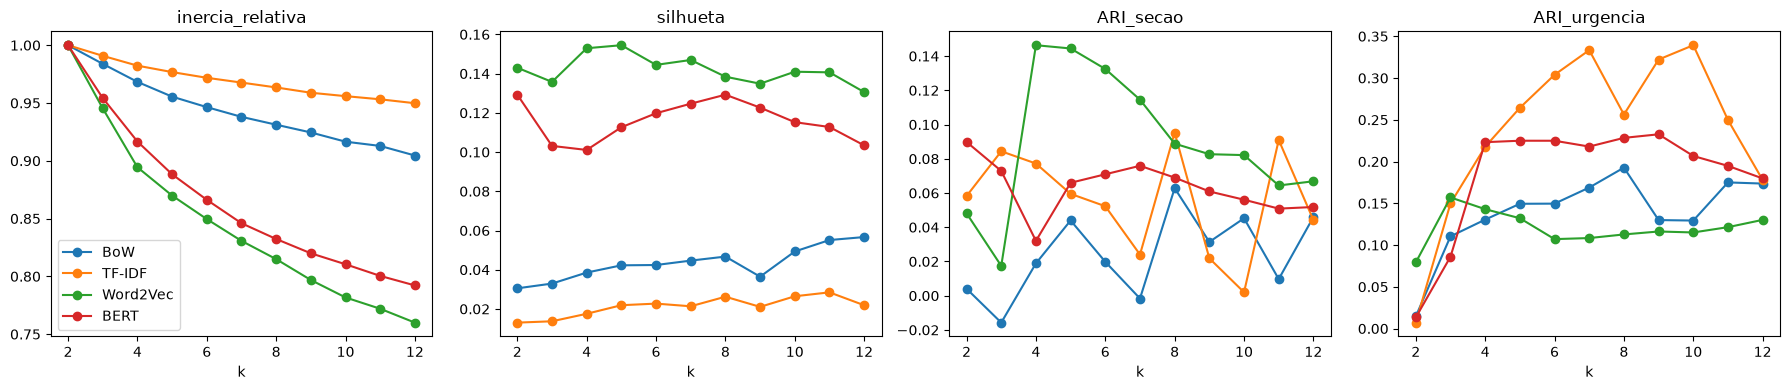

,representacao,k,silhueta,ARI_secao,ARI_urgencia
10,BoW,12,0.057,0.046,0.174
20,TF-IDF,11,0.028,0.091,0.250
25,Word2Vec,5,0.154,0.144,0.132
33,BERT,2,0.129,0.090,0.013


In [40]:
fig, eixos = plt.subplots(1, 4, figsize=(18, 4))
for coluna, eixo in zip(["inercia_relativa", "silhueta", "ARI_secao", "ARI_urgencia"], eixos):
    for nome, grupo in varredura.groupby("representacao", sort=False):
        eixo.plot(grupo["k"], grupo[coluna], marker="o", label=nome)
    eixo.set_title(coluna)
    eixo.set_xlabel("k")
eixos[0].legend()
plt.tight_layout()
plt.savefig(FIGURAS / "varredura_k.png", dpi=120)
plt.show()

display(varredura.loc[varredura.groupby("representacao", sort=False)["silhueta"].idxmax(),
                      ["representacao", "k", "silhueta", "ARI_secao", "ARI_urgencia"]].round(3))


k escolhido: maior ARI médio com a urgência

In [41]:
K = int(varredura.groupby("k")["ARI_urgencia"].mean().idxmax())
print("k escolhido:", K)

rotulos = {nome: KMeans(n_clusters=K, random_state=SEMENTE, n_init=10).fit_predict(normalize(X))
           for nome, X in REPRESENTACOES.items()}

k escolhido: 7


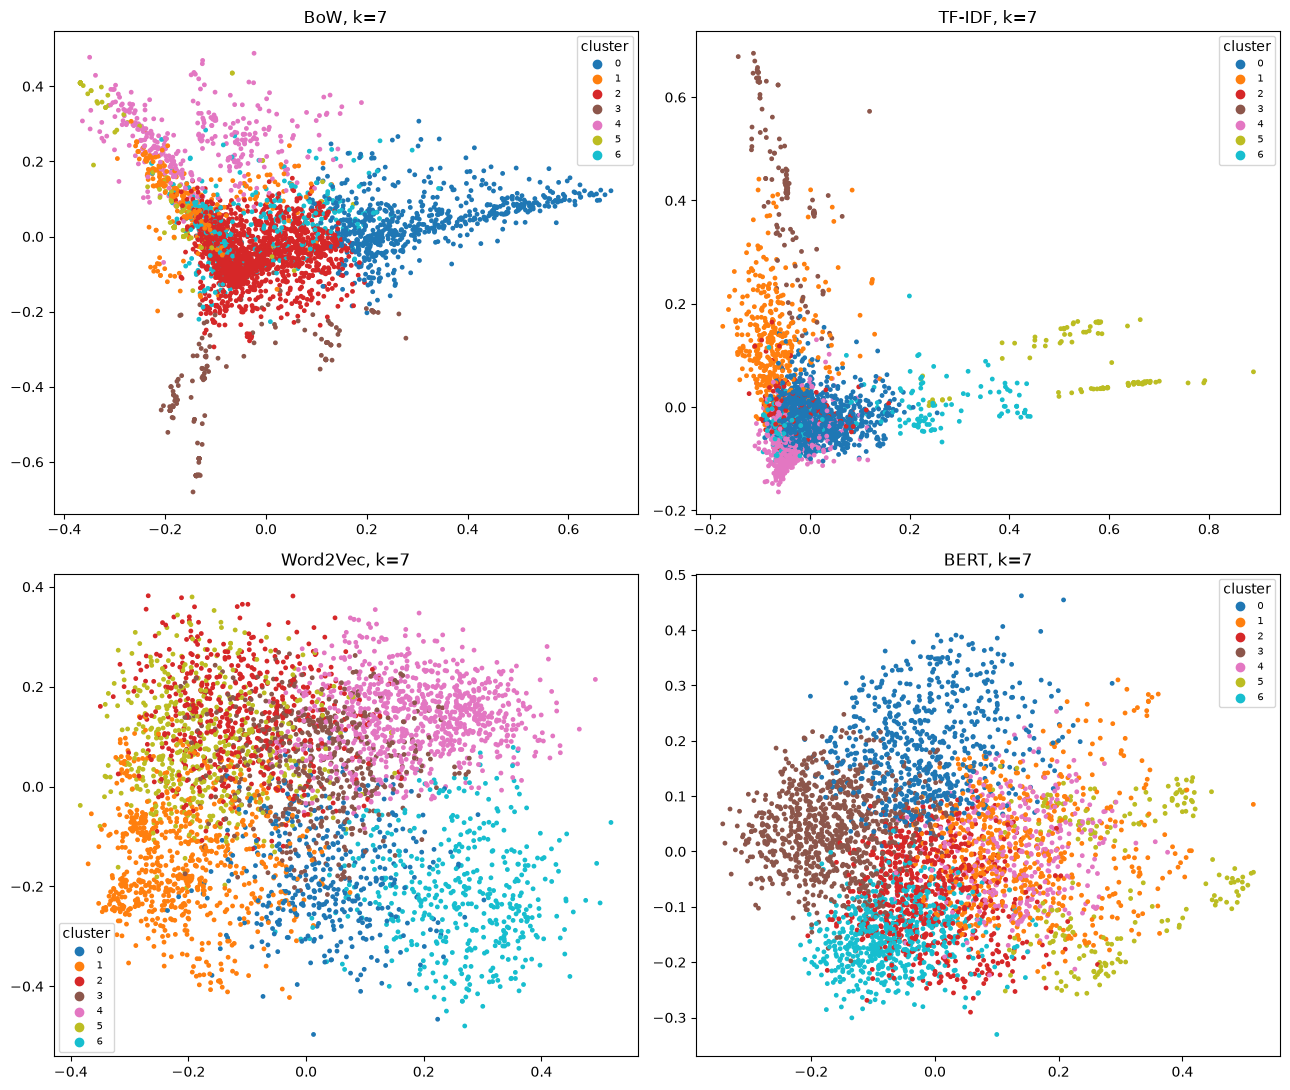

In [42]:
from sklearn.decomposition import PCA

fig, eixos = plt.subplots(2, 2, figsize=(13, 11))
for (nome, X), eixo in zip(REPRESENTACOES.items(), eixos.flat):
    denso = X.toarray() if hasattr(X, "toarray") else X
    coords = PCA(n_components=2, random_state=SEMENTE).fit_transform(normalize(denso))
    pontos = eixo.scatter(coords[:, 0], coords[:, 1], c=rotulos[nome], cmap="tab10", s=6)
    eixo.set_title(f"{nome}, k={K}")
    eixo.legend(*pontos.legend_elements(), title="cluster", fontsize=7, loc="best")
plt.tight_layout()
plt.savefig(FIGURAS / "pca_clusters.png", dpi=120)
plt.show()

termos de maior TF-IDF médio, subseção e rótulo mais frequentes por cluster

In [43]:
termos = tfidf.get_feature_names_out()


def descrever_clusters(nome):
    linhas = []
    for c in range(K):
        membros = base[rotulos[nome] == c]
        media = np.asarray(X_tfidf[membros.index].mean(axis=0)).ravel()
        secao = membros["section"].value_counts(normalize=True)
        urgencia = membros["urgency"].value_counts(normalize=True)
        linhas.append({
            "cluster": c,
            "n": len(membros),
            "termos": ", ".join(termos[np.argsort(media)[::-1][:8]]),
            "secao": f"{secao.index[0]} {secao.iloc[0]:.0%}",
            "urgencia": f"{urgencia.index[0]} {urgencia.iloc[0]:.0%}",
        })
    return pd.DataFrame(linhas)


for nome in REPRESENTACOES:
    print(f"\n=== {nome}")
    display(descrever_clusters(nome))


=== BoW


,cluster,n,termos,secao,urgencia
0,0,655,"not, drink, use, alcohol, doctor, smoke, make, take",conditions 57%,self_care 45%
1,1,310,"things, help, ease, try, symptoms, pain, may, cope",conditions 72%,self_care 73%
2,2,1932,"may, take, blood, pain, child, not, need, skin",conditions 53%,informational 56%
3,3,174,"side, effects, think, serious, might, taking, anaphylaxis, effect",medicines 89%,informational 33%
4,4,355,"get, call, online, help, pain, feel, child, temperature",conditions 65%,urgent 82%
5,5,142,"dose, prescribed, taken, more, call, take, online, go",medicines 100%,urgent 89%
6,6,432,"symptoms, not, may, include, worse, get, feeling, pain",conditions 84%,informational 46%



=== TF-IDF


,cluster,n,termos,secao,urgencia
0,0,2107,"may, not, symptoms, usually, baby, gp, child, treatment",conditions 58%,informational 63%
1,1,405,"call, online, get, help, pain, temperature, feel, high",conditions 64%,urgent 77%
2,2,244,"e, nearest, find, breathing, difficulty, chest, pain, severe",conditions 63%,emergency 93%
3,3,144,"dose, prescribed, taken, more, call, take, online, go",medicines 99%,urgent 85%
4,4,674,"not, try, drink, use, take, water, alcohol, eat",conditions 61%,self_care 76%
5,5,98,"think, might, serious, side, taking, effects, anaphylaxis, nhs",medicines 90%,urgent 56%
6,6,328,"things, help, effects, side, ease, symptoms, reduce, cope",conditions 54%,self_care 58%



=== Word2Vec


,cluster,n,termos,secao,urgencia
0,0,392,"not, drink, try, alcohol, eat, make, exercise, smoke",conditions 60%,self_care 64%
1,1,721,"side, taking, effects, dose, take, prescribed, call, more",medicines 82%,informational 53%
2,2,536,"blood, symptoms, may, heart, cancer, disease, treatment, risk",conditions 75%,informational 77%
3,3,526,"things, help, symptoms, pain, ease, not, may, gp",conditions 71%,self_care 42%
4,4,880,"pain, skin, get, not, call, feel, temperature, online",conditions 65%,urgent 30%
5,5,506,"child, help, get, think, may, health, support, gp",conditions 50%,informational 54%
6,6,439,"not, use, water, wear, try, put, skin, warm",conditions 70%,self_care 74%



=== BERT


,cluster,n,termos,secao,urgencia
0,0,637,"symptoms, may, include, blood, usually, cause, not, people",conditions 76%,informational 86%
1,1,593,"medicines, take, not, taking, doctor, effects, side, pharmacist",medicines 63%,informational 79%
2,2,706,"call, child, help, gp, get, may, not, need",conditions 47%,informational 49%
3,3,867,"pain, not, get, call, feel, online, child, very",conditions 66%,non_urgent 33%
4,4,358,"things, help, ease, symptoms, reduce, may, pain, try",conditions 71%,self_care 59%
5,5,212,"dose, prescribed, think, taken, more, serious, might, side",medicines 97%,urgent 74%
6,6,627,"not, try, use, drink, water, eat, alcohol, wear",conditions 66%,self_care 81%


métricas intra e intercluster de  coesão (similaridade média dentro do cluster) e separação (distância entre centróides)

In [44]:
from sklearn.metrics.pairwise import cosine_similarity


def coesao_e_separacao(nome):
    Xn = normalize(REPRESENTACOES[nome])
    similaridade = cosine_similarity(Xn)
    coesao = []
    for c in range(K):
        indices = np.where(rotulos[nome] == c)[0]
        sub = similaridade[np.ix_(indices, indices)]
        coesao.append(sub[np.triu_indices_from(sub, k=1)].mean())
    centroides = np.vstack([np.asarray(Xn[rotulos[nome] == c].mean(axis=0)).ravel() for c in range(K)])
    distancia = 1 - cosine_similarity(centroides)
    return {
        "representacao": nome,
        "coesao_media": np.mean(coesao),
        "similaridade_media_geral": similaridade[np.triu_indices_from(similaridade, k=1)].mean(),
        "separacao_media": distancia[np.triu_indices_from(distancia, k=1)].mean(),
    }


display(pd.DataFrame([coesao_e_separacao(n) for n in REPRESENTACOES]).round(3))

,representacao,coesao_media,similaridade_media_geral,separacao_media
0,BoW,0.227,0.055,0.696
1,TF-IDF,0.150,0.024,0.751
2,Word2Vec,0.740,0.661,0.127
3,BERT,0.813,0.768,0.083


## 3. Busca

consultas como um leigo escreveria, similaridade de cosseno contra as 4.000 passagens

In [45]:
def vetorizar_consulta(consulta, nome):
    if nome == "BoW":
        return bow.transform([preparar(consulta)])
    if nome == "TF-IDF":
        return tfidf.transform([preparar(consulta)])
    if nome == "Word2Vec":
        return vetor_w2v(preparar(consulta)).reshape(1, -1)
    return gerar_embeddings_bert([consulta])


def similaridades(consulta, nome):
    return cosine_similarity(vetorizar_consulta(consulta, nome), REPRESENTACOES[nome])[0]


def mostrar(sims, k=5):
    topo = np.argsort(sims)[::-1][:k]
    resultado = base.loc[topo, ["page_name", "urgency"]].copy()
    resultado.insert(0, "sim", sims[topo].round(3))
    resultado["trecho"] = base.loc[topo, "clean_text"].str.replace("\n", " / ").str[:90]
    return resultado.reset_index(drop=True).rename(lambda i: i + 1)


def buscar(consulta, k=5):
    print(f"\n######## {consulta}")
    for nome in REPRESENTACOES:
        print(f"\n--- {nome}")
        display(mostrar(similaridades(consulta, nome), k))


CONSULTAS = [
    "I have chest pain and I can't breathe properly",
    "my child has a high temperature and a rash",
    "can I drink alcohol while taking antibiotics",
    "I feel sad and anxious all the time and can't sleep",
]

In [46]:
buscar(CONSULTAS[0])


######## I have chest pain and I can't breathe properly

--- BoW


,sim,page_name,urgency,trecho
1,0.408,Heart valve disease,emergency,"you're struggling to breathe - you're choking, gasping and unable to speak / you have ..."
2,0.405,Latanoprost,emergency,you have chest pain / you are wheezing and find it difficult to breathe ( / asthma / o...
3,0.405,Thoracic outlet syndrome,emergency,"you have sudden breathlessness, sharp chest pain (this may be worse when you breathe i..."
4,0.405,Angina,emergency,you've been diagnosed with angina and have chest pain that does not stop after resting...
5,0.391,Costochondritis,emergency,"chest pain that started suddenly, or spreads to your arm, neck or jaw, or your chest f..."



--- TF-IDF


,sim,page_name,urgency,trecho
1,0.282,Thoracic outlet syndrome,emergency,"you have sudden breathlessness, sharp chest pain (this may be worse when you breathe i..."
2,0.264,Goitre,emergency,you're finding it hard to breathe or have a wheezing noise when you breathe / Find you...
3,0.256,Heart valve disease,emergency,"you're struggling to breathe - you're choking, gasping and unable to speak / you have ..."
4,0.255,Lung cancer,emergency,"you're struggling to breathe - you are choking, gasping and unable to speak / you have..."
5,0.239,Latanoprost,emergency,you have chest pain / you are wheezing and find it difficult to breathe ( / asthma / o...



--- Word2Vec


,sim,page_name,urgency,trecho
1,0.857,Heart valve disease,emergency,"you're struggling to breathe - you're choking, gasping and unable to speak / you have ..."
2,0.849,Costochondritis,emergency,"chest pain that started suddenly, or spreads to your arm, neck or jaw, or your chest f..."
3,0.844,Pleurisy,emergency,you have sudden chest pain that lasts for 15 minutes or more / you have sudden chest p...
4,0.843,Thoracic outlet syndrome,emergency,"you have sudden breathlessness, sharp chest pain (this may be worse when you breathe i..."
5,0.834,Lung cancer,emergency,"you're struggling to breathe - you are choking, gasping and unable to speak / you have..."



--- BERT


,sim,page_name,urgency,trecho
1,0.732,Swollen arms and hands (oedema),emergency,"you feel short of breath or are struggling to breathe / your chest feels tight, heavy ..."
2,0.716,Lung cancer,emergency,"you're struggling to breathe - you are choking, gasping and unable to speak / you have..."
3,0.713,Supraventricular tachycardia (SVT),emergency,you've been diagnosed with supraventricular tachycardia (SVT) and your episode has las...
4,0.712,Gastroscopy,emergency,you keep being sick / you're vomiting blood / you are short of breath / you have sever...
5,0.711,"Swollen ankles, feet and legs (oedema)",emergency,"you feel short of breath or are struggling to breathe / your chest feels tight, heavy ..."


In [47]:
buscar(CONSULTAS[1])


######## my child has a high temperature and a rash

--- BoW


,sim,page_name,urgency,trecho
1,0.672,How to take your baby's temperature,non_urgent,You can usually look after your baby or child at home when they have a high temperatur...
2,0.607,COVID-19,urgent,you're worried about your or a child's COVID-19 symptoms or are not sure what to do / ...
3,0.577,High temperature (fever) in children,self_care,"If your child or baby has a high temperature, you can usually look after them at home...."
4,0.556,High temperature (fever) in children,urgent,"is under 3 months old and has a temperature of 38C or higher, or you think they have a..."
5,0.530,MenB vaccine for children,urgent,"is under 3 months old and has a temperature of 38C or higher, or you think they have a..."



--- TF-IDF


,sim,page_name,urgency,trecho
1,0.591,How to take your baby's temperature,non_urgent,You can usually look after your baby or child at home when they have a high temperatur...
2,0.561,COVID-19,urgent,you're worried about your or a child's COVID-19 symptoms or are not sure what to do / ...
3,0.514,High temperature (fever) in children,self_care,"If your child or baby has a high temperature, you can usually look after them at home...."
4,0.497,High temperature (fever) in children,urgent,"is under 3 months old and has a temperature of 38C or higher, or you think they have a..."
5,0.458,MenB vaccine for children,urgent,"is under 3 months old and has a temperature of 38C or higher, or you think they have a..."



--- Word2Vec


,sim,page_name,urgency,trecho
1,0.869,High temperature (fever) in children,urgent,"is under 3 months old and has a temperature of 38C or higher, or you think they have a..."
2,0.867,High temperature (fever) in children,self_care,"If your child or baby has a high temperature, you can usually look after them at home...."
3,0.867,Roseola,urgent,is under 3 months old and has a temperature of 38C or higher (or you think they have a...
4,0.861,Pneumococcal vaccine,urgent,"is 3 to 6 months old and has a temperature of 39C or higher, or you think they have a ..."
5,0.860,MenB vaccine for children,urgent,"is under 3 months old and has a temperature of 38C or higher, or you think they have a..."



--- BERT


,sim,page_name,urgency,trecho
1,0.800,Heat rash (prickly heat),non_urgent,you have heat rash that does not improve after a few days / your baby has a rash and y...
2,0.770,Roseola,urgent,Speak to a GP if you or your child has a weakened immune system and has had contact wi...
3,0.770,Cystoscopy,emergency,you cannot pee and your tummy is swollen and painful
4,0.767,Pityriasis rosea,urgent,you have a new rash and you're pregnant / Getting pityriasis rosea in the first 15 wee...
5,0.765,Rubella (german measles),urgent,You're pregnant and either: / you have a new rash / you've been in close contact with ...


In [48]:
buscar(CONSULTAS[2])


######## can I drink alcohol while taking antibiotics

--- BoW


,sim,page_name,urgency,trecho
1,0.453,Alcohol poisoning,informational,"Alcohol poisoning is usually caused by binge drinking, which is where you have a lot o..."
2,0.442,Type 1 diabetes,self_care,do not drink too much alcohol - keep to the recommended guidelines of no more than 14 ...
3,0.442,Giardiasis,self_care,To look after yourself while you have giardiasis: / use oral rehydration sachets you m...
4,0.401,Carbamazepine (Tegretol),informational,"Taking carbamazepine with other medicines, such as hormonal contraception, HRT and ant..."
5,0.379,Felodipine,informational,"There are some medicines, remedies and supplements that may not mix well with felodipi..."



--- TF-IDF


,sim,page_name,urgency,trecho
1,0.463,Cirrhosis,self_care,do not drink alcohol / do not smoke
2,0.420,Type 1 diabetes,self_care,do not drink too much alcohol - keep to the recommended guidelines of no more than 14 ...
3,0.418,PMS (premenstrual syndrome),self_care,do not smoke / do not drink too much alcohol
4,0.404,Alcohol poisoning,informational,"Alcohol poisoning is usually caused by binge drinking, which is where you have a lot o..."
5,0.360,Giardiasis,self_care,To look after yourself while you have giardiasis: / use oral rehydration sachets you m...



--- Word2Vec


,sim,page_name,urgency,trecho
1,0.878,Brain aneurysm,self_care,do not drink too much alcohol / do not take illegal drugs
2,0.872,Alcohol poisoning,informational,"Alcohol poisoning is usually caused by binge drinking, which is where you have a lot o..."
3,0.862,Type 1 diabetes,self_care,do not drink too much alcohol - keep to the recommended guidelines of no more than 14 ...
4,0.861,Ulcerative colitis,self_care,"do not take NSAIDs (non-steroidal anti-inflammatory drugs), such as ibuprofen or aspir..."
5,0.860,Cirrhosis,self_care,do not drink alcohol / do not smoke



--- BERT


,sim,page_name,urgency,trecho
1,0.724,Food allergy,self_care,do not eat foods without checking what ingredients are in them first / do not cut food...
2,0.701,Ways to help avoid self-harm,informational,Information: / Mind - Self-harm: helping yourself now
3,0.694,Lithium,informational,Do not stop taking lithium suddenly or change your dose without speaking to your docto...
4,0.690,Lithium,emergency,"you take more than your prescribed dose of lithium, even if you do not feel any different"
5,0.688,Sunburn,self_care,You can ask a pharmacist: / about the best sunburn treatments / if you need to see a GP


In [49]:
buscar(CONSULTAS[3])


######## I feel sad and anxious all the time and can't sleep

--- BoW


,sim,page_name,urgency,trecho
1,0.612,Anxiety in pregnancy,non_urgent,you're pregnant and you feel anxious all the time
2,0.548,Sleep paralysis,non_urgent,You often have sleep paralysis and you feel: / very anxious or scared to go to sleep /...
3,0.417,Scurvy,non_urgent,You or your child are at risk of scurvy and: / feel very tired and weak all the time /...
4,0.408,Jet lag,self_care,do not sleep during the day - only sleep at night time
5,0.295,Sleep apnoea,non_urgent,"You have any of the main symptoms of sleep apnoea, such as: / your breathing stops and..."



--- TF-IDF


,sim,page_name,urgency,trecho
1,0.493,Anxiety in pregnancy,non_urgent,you're pregnant and you feel anxious all the time
2,0.399,Sleep paralysis,non_urgent,You often have sleep paralysis and you feel: / very anxious or scared to go to sleep /...
3,0.316,Jet lag,self_care,do not sleep during the day - only sleep at night time
4,0.307,Scurvy,non_urgent,You or your child are at risk of scurvy and: / feel very tired and weak all the time /...
5,0.248,Mental health,self_care,There are things you can do to help your seasonal affective disorder (SAD) symptoms.



--- Word2Vec


,sim,page_name,urgency,trecho
1,0.934,Sleep paralysis,non_urgent,You often have sleep paralysis and you feel: / very anxious or scared to go to sleep /...
2,0.872,Anxiety in pregnancy,non_urgent,you're pregnant and you feel anxious all the time
3,0.861,Changes in the last hours and days of life,informational,"You'll start to feel more tired and drowsy, and have less energy. You'll probably spen..."
4,0.857,Mental health,informational,"A general low mood can make you feel sad, anxious or panicky, angry or frustrated and ..."
5,0.847,Narcolepsy,informational,Narcolepsy is a rare long-term brain condition that can prevent a person from choosing...



--- BERT


,sim,page_name,urgency,trecho
1,0.779,Sleep paralysis,non_urgent,You often have sleep paralysis and you feel: / very anxious or scared to go to sleep /...
2,0.735,Excessive daytime sleepiness (hypersomnia),non_urgent,you often fall asleep during the day / sleepiness is affecting your life
3,0.714,Gastritis,non_urgent,you have tummy pain or indigestion for longer than 1 week / your tummy pain is getting...
4,0.713,Malignant brain tumour (brain cancer),non_urgent,"you have headaches that keep coming back, make you feel sick, or do not go away when y..."
5,0.710,Stomach ulcer,urgent,You have symptoms of a stomach ulcer and: / your tummy pain is getting worse or does n...


combinação: média das similaridades do TF-IDF e do BERT, reescaladas de 0 a 1

In [50]:
def reescalar(s):
    return (s - s.min()) / (s.max() - s.min())


def buscar_combinado(consulta, k=5):
    sims = (reescalar(similaridades(consulta, "TF-IDF")) + reescalar(similaridades(consulta, "BERT"))) / 2
    print(f"\n######## {consulta}  (TF-IDF + BERT)")
    display(mostrar(sims, k))


for consulta in CONSULTAS:
    buscar_combinado(consulta)


######## I have chest pain and I can't breathe properly  (TF-IDF + BERT)


,sim,page_name,urgency,trecho
1,0.926,Lung cancer,emergency,"you're struggling to breathe - you are choking, gasping and unable to speak / you have..."
2,0.923,Thoracic outlet syndrome,emergency,"you have sudden breathlessness, sharp chest pain (this may be worse when you breathe i..."
3,0.895,Heart valve disease,emergency,"you're struggling to breathe - you're choking, gasping and unable to speak / you have ..."
4,0.866,Goitre,emergency,you're finding it hard to breathe or have a wheezing noise when you breathe / Find you...
5,0.850,Gastroscopy,emergency,you keep being sick / you're vomiting blood / you are short of breath / you have sever...



######## my child has a high temperature and a rash  (TF-IDF + BERT)


,sim,page_name,urgency,trecho
1,0.869,How to take your baby's temperature,non_urgent,You can usually look after your baby or child at home when they have a high temperatur...
2,0.831,COVID-19,urgent,you're worried about your or a child's COVID-19 symptoms or are not sure what to do / ...
3,0.824,Heat rash (prickly heat),non_urgent,you have heat rash that does not improve after a few days / your baby has a rash and y...
4,0.821,High temperature (fever) in children,self_care,"If your child or baby has a high temperature, you can usually look after them at home...."
5,0.771,High temperature (fever) in children,urgent,"is under 3 months old and has a temperature of 38C or higher, or you think they have a..."



######## can I drink alcohol while taking antibiotics  (TF-IDF + BERT)


,sim,page_name,urgency,trecho
1,0.840,Type 1 diabetes,self_care,do not drink too much alcohol - keep to the recommended guidelines of no more than 14 ...
2,0.839,Alcohol poisoning,informational,"Alcohol poisoning is usually caused by binge drinking, which is where you have a lot o..."
3,0.785,Giardiasis,self_care,To look after yourself while you have giardiasis: / use oral rehydration sachets you m...
4,0.764,Blushing,self_care,do not eat spicy foods or drink alcohol or hot drinks if they make you blush
5,0.758,PMS (premenstrual syndrome),self_care,do not smoke / do not drink too much alcohol



######## I feel sad and anxious all the time and can't sleep  (TF-IDF + BERT)


,sim,page_name,urgency,trecho
1,0.905,Sleep paralysis,non_urgent,You often have sleep paralysis and you feel: / very anxious or scared to go to sleep /...
2,0.898,Anxiety in pregnancy,non_urgent,you're pregnant and you feel anxious all the time
3,0.684,Scurvy,non_urgent,You or your child are at risk of scurvy and: / feel very tired and weak all the time /...
4,0.670,Jet lag,self_care,do not sleep during the day - only sleep at night time
5,0.564,Tinnitus,non_urgent,you have tinnitus regularly or constantly / your tinnitus is getting worse / your tinn...


## 4. Classificação

rótulo: nível de urgência dos care cards, dado pelo próprio NHS. Regressão Logística em cada representação, 80/20

In [51]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

CLASSES = ["emergency", "urgent", "non_urgent", "self_care"]
rot = base[base["urgency"] != "informational"]
idx_treino, idx_teste = train_test_split(rot.index, test_size=0.2, stratify=rot["urgency"],
                                         random_state=SEMENTE)
y_treino, y_teste = base.loc[idx_treino, "urgency"], base.loc[idx_teste, "urgency"]
print(f"treino: {len(idx_treino):,}   teste: {len(idx_teste):,}")

treino: 1,908   teste: 478


BoW e TF-IDF ajustados só no treino

In [52]:
vet_bow = CountVectorizer(analyzer=lambda t: t, min_df=2).fit(base.loc[idx_treino, "tokens"])
vet_tfidf = TfidfVectorizer(analyzer=lambda t: t, min_df=2).fit(base.loc[idx_treino, "tokens"])

VETORIZAR = {
    "BoW": lambda textos: vet_bow.transform([preparar(t) for t in textos]),
    "TF-IDF": lambda textos: vet_tfidf.transform([preparar(t) for t in textos]),
    "Word2Vec": lambda textos: np.vstack([vetor_w2v(preparar(t)) for t in textos]),
    "BERT": lambda textos: gerar_embeddings_bert(list(textos)),
}
FEATURES = {
    "BoW": lambda idx: vet_bow.transform(base.loc[idx, "tokens"]),
    "TF-IDF": lambda idx: vet_tfidf.transform(base.loc[idx, "tokens"]),
    "Word2Vec": lambda idx: X_w2v[idx],
    "BERT": lambda idx: X_bert[idx],
}

classificadores, previsoes, resultados = {}, {}, []
for nome in REPRESENTACOES:
    modelo = LogisticRegression(max_iter=3000).fit(FEATURES[nome](idx_treino), y_treino)
    classificadores[nome] = modelo
    previsoes[nome] = modelo.predict(FEATURES[nome](idx_teste))
    resultados.append({"representacao": nome,
                       "acuracia": accuracy_score(y_teste, previsoes[nome]),
                       "f1_macro": f1_score(y_teste, previsoes[nome], average="macro")})

display(pd.DataFrame(resultados).round(3))

,representacao,acuracia,f1_macro
0,BoW,0.912,0.905
1,TF-IDF,0.921,0.914
2,Word2Vec,0.921,0.910
3,BERT,0.925,0.909


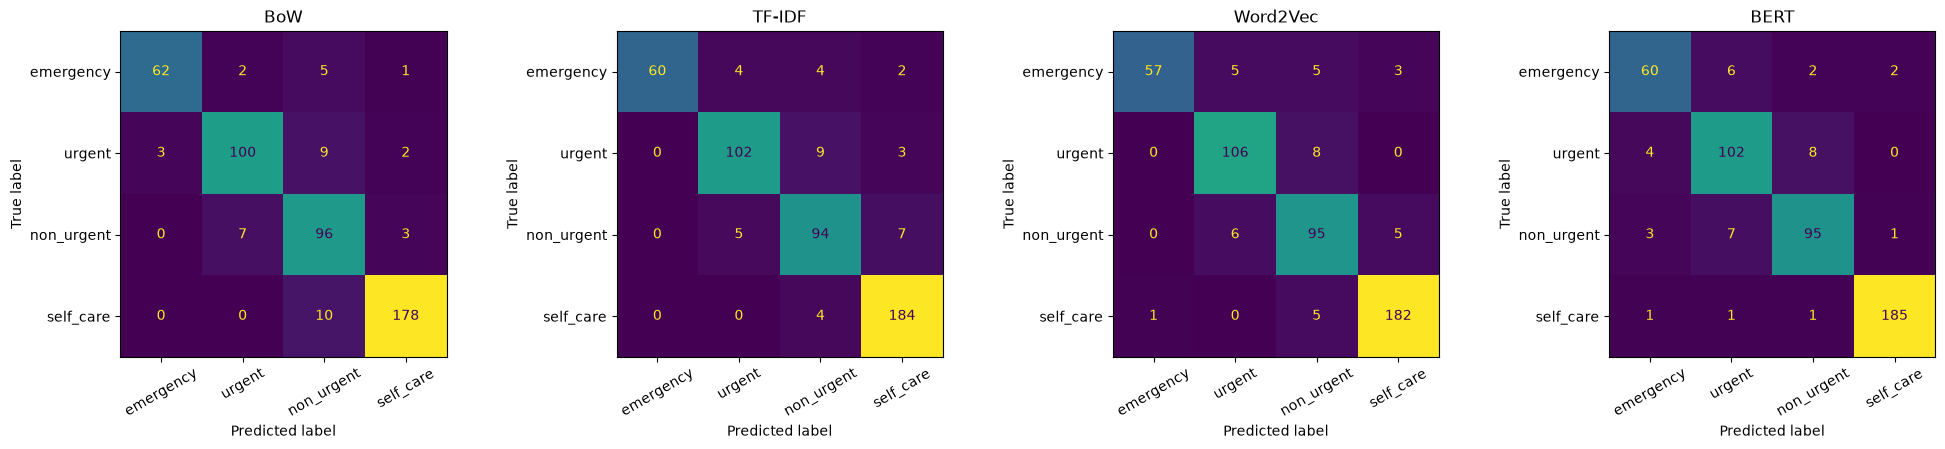

relatório da melhor representação (TF-IDF):

              precision    recall  f1-score   support

   emergency       1.00      0.86      0.92        70
      urgent       0.92      0.89      0.91       114
  non_urgent       0.85      0.89      0.87       106
   self_care       0.94      0.98      0.96       188

    accuracy                           0.92       478
   macro avg       0.93      0.90      0.91       478
weighted avg       0.92      0.92      0.92       478



In [53]:
fig, eixos = plt.subplots(1, 4, figsize=(20, 4.5))
for nome, eixo in zip(REPRESENTACOES, eixos):
    ConfusionMatrixDisplay.from_predictions(y_teste, previsoes[nome], labels=CLASSES, ax=eixo,
                                            colorbar=False, xticks_rotation=30)
    eixo.set_title(nome)
plt.tight_layout()
plt.savefig(FIGURAS / "matrizes_confusao.png", dpi=120)
plt.show()

melhor = max(resultados, key=lambda r: r["f1_macro"])["representacao"]
print(f"relatório da melhor representação ({melhor}):\n")
print(classification_report(y_teste, previsoes[melhor], labels=CLASSES))

termos de maior peso por classe no TF-IDF

In [54]:
nomes = vet_tfidf.get_feature_names_out()
pesos = classificadores["TF-IDF"]
display(pd.DataFrame({classe: nomes[np.argsort(pesos.coef_[i])[::-1][:10]]
                      for i, classe in enumerate(pesos.classes_)})[CLASSES])

,emergency,urgent,non_urgent,self_care
0,e,call,gp,things
1,nearest,online,weeks,try
2,anaphylaxis,get,think,use
3,breathing,effects,symptoms,ease
4,chest,prescribed,away,help
5,find,help,diabetes,not
6,seizure,taken,lump,make
7,severe,dose,affecting,drink
8,difficulty,more,getting,pharmacist
9,breathe,serious,health,avoid


dados novos: frases fora do corpus, no estilo dos care cards e no de um paciente

In [55]:
NOVOS = pd.DataFrame([
    ("you suddenly cannot breathe and your lips are turning blue", "emergency"),
    ("your child has a rash that does not fade when you press a glass against it", "emergency"),
    ("your leg is swollen, red and painful and it is getting worse quickly", "urgent"),
    ("you have had a cough for more than 3 weeks", "non_urgent"),
    ("drink plenty of fluids and get lots of rest", "self_care"),
    ("my head hurts a bit since yesterday, nothing serious", "self_care"),
    ("I think I'm having a heart attack", "emergency"),
    ("I've been feeling low for a few weeks and it's not getting better", "non_urgent"),
], columns=["texto", "esperado"])

for nome in REPRESENTACOES:
    NOVOS[nome] = classificadores[nome].predict(VETORIZAR[nome](NOVOS["texto"]))

display(NOVOS)
print("acertos por representação:")
print(NOVOS[list(REPRESENTACOES)].eq(NOVOS["esperado"], axis=0).sum().to_string())

,texto,esperado,BoW,TF-IDF,Word2Vec,BERT
0,you suddenly cannot breathe and your lips are turning blue,emergency,emergency,emergency,emergency,emergency
1,your child has a rash that does not fade when you press a glass against it,emergency,non_urgent,self_care,emergency,non_urgent
2,"your leg is swollen, red and painful and it is getting worse quickly",urgent,non_urgent,non_urgent,non_urgent,urgent
3,you have had a cough for more than 3 weeks,non_urgent,non_urgent,non_urgent,non_urgent,non_urgent
4,drink plenty of fluids and get lots of rest,self_care,self_care,self_care,self_care,self_care
5,"my head hurts a bit since yesterday, nothing serious",self_care,non_urgent,self_care,emergency,non_urgent
6,I think I'm having a heart attack,emergency,non_urgent,emergency,emergency,emergency
7,I've been feeling low for a few weeks and it's not getting better,non_urgent,non_urgent,non_urgent,non_urgent,non_urgent


acertos por representação:
BoW         4
TF-IDF      6
Word2Vec    6
BERT        6


## 5. Sentimento, entidades nomeadas e relações

### 5.1 Sentimento

VADER do NLTK, `compound` de -1 a +1

In [56]:
nltk.download("vader_lexicon", quiet=True)
from nltk.sentiment import SentimentIntensityAnalyzer

vader = SentimentIntensityAnalyzer()
base["compound"] = [vader.polarity_scores(t)["compound"] for t in base["clean_text"]]

display(base.groupby("urgency")["compound"].agg(
    media="mean", negativas=lambda s: (s < -0.05).mean(), positivas=lambda s: (s > 0.05).mean()
).reindex(CLASSES + ["informational"]).round(2))

,media,negativas,positivas
urgency,,,
emergency,-0.58,0.85,0.05
urgent,-0.21,0.57,0.27
non_urgent,-0.37,0.69,0.15
self_care,0.15,0.32,0.55
informational,-0.11,0.51,0.35


In [57]:
print("Mais negativas:")
display(base.nsmallest(3, "compound")[["compound", "urgency", "clean_text"]]
        .assign(clean_text=lambda d: d["clean_text"].str.replace("\n", " / ").str[:110]))
print("Mais positivas:")
display(base.nlargest(3, "compound")[["compound", "urgency", "clean_text"]]
        .assign(clean_text=lambda d: d["clean_text"].str.replace("\n", " / ").str[:110]))

Mais negativas:


,compound,urgency,clean_text
1576,-0.9990,urgent,How does buprenorphine work? / Buprenorphine is from a group of medicines called opioi...
2730,-0.9988,urgent,How does fentanyl work? / Fentanyl is from a group of medicines called opioids or narc...
2765,-0.9981,emergency,Rash caused by heat / An example of heat rash (prickly heat). / Credit: Disney Magic /...


Mais positivas:


,compound,urgency,clean_text
3491,0.9967,informational,There are a range of benefits that you and your carer (if you have one) may be entitle...
1770,0.9964,informational,"If your child is being treated for an eating disorder, their treatment team will play ..."
3566,0.9963,informational,How does senna work? / Senna is a type of laxative called a stimulant laxative. It sti...


### 5.2 Entidades nomeadas

spaCy `en_core_web_sm`, amostra de 300 passagens

In [58]:
import spacy, subprocess, sys

try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    subprocess.run([sys.executable, "-m", "spacy", "download", "en_core_web_sm"], check=True)
    nlp = spacy.load("en_core_web_sm")

amostra_ner = base.sample(300, random_state=SEMENTE)
entidades = pd.DataFrame([(e.text, e.label_) for doc in nlp.pipe(amostra_ner["clean_text"])
                          for e in doc.ents], columns=["entidade", "rotulo"])

print(f"{len(entidades):,} entidades em 300 passagens\n")
display(entidades["rotulo"].value_counts().rename("ocorrencias").to_frame())
display(entidades.value_counts().head(15).rename("ocorrencias").to_frame())

500 entidades em 300 passagens



,ocorrencias
rotulo,
ORG,153
DATE,119
CARDINAL,113
TIME,49
PERSON,24
GPE,19
ORDINAL,9
NORP,6
PERCENT,4


,,ocorrencias
entidade,rotulo,
111,CARDINAL,49
GP,ORG,49
1,CARDINAL,13
2,CARDINAL,12
CT,ORG,11
a few days,DATE,10
A&E,ORG,9
NHS,ORG,9
first,ORDINAL,7


avaliação manual: entidades de uma passagem de sintomas

In [59]:
exemplo = base[(base["urgency"] == "emergency") & base["clean_text"].str.contains("chest pain")].iloc[0]
doc = nlp(exemplo["clean_text"])
print(exemplo["page_name"], "\n")
print(exemplo["clean_text"][:400], "\n")
print("entidades:", [(e.text, e.label_) for e in doc.ents])

Whooping cough 

your or your child's lips, tongue, face or skin suddenly turn blue or grey (on black or brown skin this may be easier to see on the palms of the hands or the soles of the feet)
you or your child are finding it hard to breathe properly (shallow breathing)
you or your child have chest pain that's worse when breathing or coughing - this could be a sign of pneumonia
your child is having seizures (fits 

entidades: [('A&E', 'ORG')]


### 5.3 Relações

sujeito–verbo–objeto (Aula 9) nas linhas dos care cards de emergência e urgência

In [60]:
def svo(linha):
    doc = nlp(linha)
    for token in doc:
        if token.pos_ in ("VERB", "AUX") and token.dep_ == "ROOT":
            sujeitos = [t for t in token.children if t.dep_ in ("nsubj", "nsubjpass")]
            objetos = [t for t in token.children if t.dep_ in ("dobj", "attr", "acomp", "oprd")]
            if sujeitos and objetos:
                objeto = doc[objetos[0].left_edge.i: objetos[0].right_edge.i + 1].text
                return sujeitos[0].text, token.lemma_, objeto
    return None


graves = base[base["urgency"].isin(["emergency", "urgent"])]
linhas = [(p["page_name"], p["urgency"], l) for _, p in graves.iterrows()
          for l in p["clean_text"].split("\n") if l.lower().startswith(("you ", "your ", "they ", "your child"))]

relacoes = []
for pagina, nivel, linha in linhas:
    tripla = svo(linha)
    if tripla:
        relacoes.append({"condicao": pagina, "nivel": nivel, "sujeito": tripla[0],
                         "verbo": tripla[1], "sinal": tripla[2]})
relacoes = pd.DataFrame(relacoes)

print(f"linhas de sinal analisadas: {len(linhas):,}")
print(f"relações extraídas        : {len(relacoes):,} ({len(relacoes) / len(linhas):.0%})\n")
display(relacoes["verbo"].value_counts().head(8).rename("ocorrencias").to_frame())
display(relacoes.sample(12, random_state=SEMENTE))

linhas de sinal analisadas: 1,728
relações extraídas        : 1,406 (81%)



,ocorrencias
verbo,
have,624
call,288
be,146
feel,90
take,60
get,51
become,13
turn,12


,condicao,nivel,sujeito,verbo,sinal
1075,Herpes simplex eye infections,emergency,You,have,a red eye
1015,Pelvic pain,urgent,you,have,pain
650,Bile duct cancer (cholangiocarcinoma),urgent,skin,turn,yellow
447,Joint pain,urgent,you,have,joint pain and the skin around it
1290,Bowel polyps,urgent,You,call,111
339,Toxoplasmosis,urgent,You,call,111
914,Swollen arms and hands (oedema),urgent,You,call,111
101,Smelly urine,urgent,you,feel,confused or agitated
70,Rosacea,urgent,you,have,a red eye
764,Cough,urgent,you,have,a hacking cough
